# Student Performance ML Pipeline — Analysis

This notebook is a compact portfolio walkthrough of the refactored workflow. The original course assessment structure has been removed; reusable logic lives in `src/student_performance/`.

**Primary design goal:** keep all learned preprocessing inside scikit-learn pipelines so the test set cannot influence imputation or scaling.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

from student_performance.data import load_dataset, clean_training_frame, select_features_and_target
from student_performance.modeling import build_svm_pipeline, build_random_forest_pipeline
from student_performance.evaluate import classification_metrics, classification_report_frame

DATA = ROOT / "data" / "raw" / "student_performance.csv"
print("Data path:", DATA.relative_to(ROOT))

Data path: data/raw/student_performance.csv


## 1. Load and audit the data

The deterministic cleaning stage removes impossible absence values and audits `GradeClass` against the documented GPA thresholds. Missing feature values are **not** imputed here; imputation is deferred to the training pipeline.

In [2]:
raw = load_dataset(DATA)
clean, audit = clean_training_frame(raw)
pd.Series(audit, name="value")

rows_input                              2100
rows_after_absence_filter               2098
invalid_absence_rows_removed               2
grade_label_mismatches_found             100
missing_study_time_left_for_pipeline      21
Name: value, dtype: int64

## 2. Exploratory checks

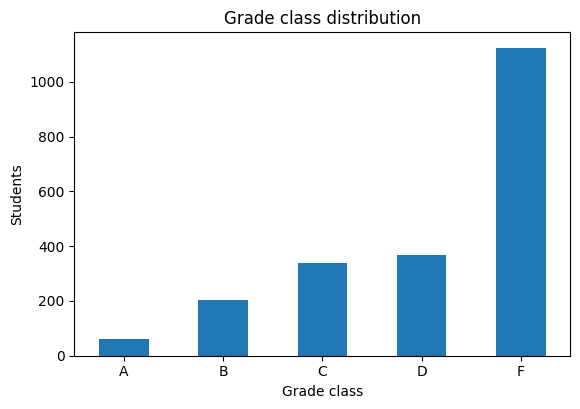

GradeClass
A     2.91
B     9.72
C    16.16
D    17.59
F    53.62
Name: percent, dtype: Float64


In [3]:
grade_order = ["A", "B", "C", "D", "F"]
counts = clean["GradeClass"].value_counts().reindex(grade_order, fill_value=0)
ax = counts.plot(kind="bar", figsize=(6.4, 4.2), title="Grade class distribution")
ax.set_xlabel("Grade class")
ax.set_ylabel("Students")
ax.tick_params(axis="x", rotation=0)
plt.show()

print((counts / counts.sum() * 100).round(2).rename("percent"))

In [4]:
corr_study = clean["GPA"].corr(clean["StudyTimeWeekly"])
corr_abs = clean["GPA"].corr(clean["Absences"])
pd.Series({
    "GPA vs StudyTimeWeekly": corr_study,
    "GPA vs Absences": corr_abs,
}, name="Pearson r").round(3)

GPA vs StudyTimeWeekly    0.18
GPA vs Absences          -0.92
Name: Pearson r, dtype: float64

The strong negative association between GPA and absences is descriptive, not causal. The dataset is suitable for demonstrating a classification workflow, but it should not be used to make causal claims about student behaviour.

## 3. Leakage-safe train/test split and model pipelines

`GPA` and `StudentID` are deliberately excluded from predictors. `GPA` defines the grade label, so using it as an input feature would make the task trivial and invalid.

In [5]:
from sklearn.model_selection import train_test_split

X, y, numeric_features, categorical_features = select_features_and_target(clean)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.70, stratify=y, random_state=66
)

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Train / test:", X_train.shape, X_test.shape)

Numeric features: ['Age', 'StudyTimeWeekly', 'Absences']
Categorical features: ['ParentalSupport']
Train / test: (1468, 4) (630, 4)


In [6]:
models = {
    "SVM baseline": build_svm_pipeline(numeric_features, categorical_features),
    "Random Forest": build_random_forest_pipeline(numeric_features, categorical_features),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({"model": name, **classification_metrics(y_test, pred)})

pd.DataFrame(rows).set_index("model").round(3)

,accuracy,macro_f1,balanced_accuracy
model,,,
SVM baseline,0.714,0.565,0.605
Random Forest,0.721,0.528,0.518


## 4. Per-class evaluation

Macro-F1 is the main comparison metric because the five grade classes are imbalanced.

In [7]:
svm = models["SVM baseline"]
svm_pred = svm.predict(X_test)
classification_report_frame(y_test, svm_pred).round(3)

,precision,recall,f1-score,support
A,0.343,0.667,0.453,18.000
B,0.404,0.344,0.372,61.000
C,0.529,0.529,0.529,102.000
D,0.519,0.613,0.562,111.000
F,0.952,0.873,0.910,338.000
accuracy,0.714,0.714,0.714,0.714
macro avg,0.549,0.605,0.565,630.000
weighted avg,0.737,0.714,0.722,630.000


## 5. Tuned-model result

The full tuning run is performed by `scripts/run_experiment.py`. The checked-in experiment searches scaler choice, `C`, and `gamma` with 5-fold stratified cross-validation scored by macro-F1.

In [8]:
pd.read_csv(ROOT / "results" / "metrics.csv", index_col="model").round(3)

,accuracy,macro_f1,balanced_accuracy
model,,,
svm_baseline,0.714,0.565,0.605
random_forest,0.721,0.528,0.518
svm_tuned,0.727,0.585,0.629


In [9]:
pd.read_csv(ROOT / "results" / "svm_tuned_best_params.csv")

,classifier__C,classifier__gamma,preprocessor__numeric__scaler
0,15.0,0.2,RobustScaler()


## Takeaways

- Putting imputation and encoding inside the sklearn pipeline prevents leakage.
- Accuracy alone is misleading for this imbalanced target; macro-F1 and balanced accuracy provide a better view.
- The tuned RBF SVM improves minority-class balance over the Random Forest baseline.
- The project is a technical demonstration, not a causal model of educational outcomes.